# SCoRe: Temporal Latent Fusion for Sequential 3D Shape Completion — Korean Melon Growth Monitoring

**Paper:** *Temporal latent fusion for sequential 3D shape completion in on-plant Korean melon growth monitoring* (SSRN preprint, DOI [10.2139/ssrn.7417106](https://doi.org/10.2139/ssrn.7417106)).
**Code:** [`sungjay-kim/SCoRe`](https://github.com/sungjay-kim/SCoRe) @ commit `b8fc9c652f30865e808be012aa3a89c0f5c42aaf` (Apache-2.0 inherited per upstream; see repo LICENSE).
**Data:** [`Sungjay/3DKoreanMelon`](https://huggingface.co/datasets/Sungjay/3DKoreanMelon) (CC BY 4.0, ~334 MB full; this notebook downloads a small subset).
**Weights:** release [`v1.0`](https://github.com/sungjay-kim/SCoRe/releases/tag/v1.0) — `score-weights-v1.0.tar.gz` (~31 MB). Note: the repository docs reference a `v1.1` bundle that does not exist; only `v1.0` is published.

**Scope (executed here):** released-model **inference only** on a small deterministic subset of the held-out test fruits (greenhouse `C`). For each selected fruit we run the author's `temporal/test.py` twice over its visit sequence — the single-frame CoRe++ baseline (`--static`) and **SCoRe** (`--fusion_mode ema_max --ema_tau 3.0`, the paper's parameter-free time-aware EMA + PC1 monotone clamp) — then compute last-frame volume RMSE / F1@5mm on the subset and visualize input vs. prediction vs. reference.

**Not done here:** the full 79-fruit benchmark, any training, occlusion sweeps. Subset metrics are **not** paper-level results (paper full test set: chamfer 2.95 mm, F1@5mm 83.0 %, volume RMSE 50.6 mL; author-documented public-path values 2.97 / 82.7 / 52.3).

**AI-assisted glue (stated explicitly):** the authors did not provide this Colab notebook. All scientific operations run the authors' pinned code unmodified; the AI-authored parts are (a) the deterministic 3-fruit subset selection, (b) adapting the pinned public config's *paths* to the actually-released v1.0 bundle (verified at runtime), and (c) metric aggregation from the author CSV. Every adaptation is printed when it runs.

日本語: このノートブックは論文「SCoRe(時系列潜変数融合による連続3D形状補間)」の公開済み学習済みモデルを、テスト分割のメロン数個体の来園シーケンスで推論するデモです。学習は行いません。著者コードをピン留めコミットのまま実行し、AIが追記した部分(サブセット選択・設定パスの適合・集計)は実行時に明示します。


## Runtime selection

The method is a small PCE-large point-cloud encoder + DeepSDF decoder MLP: it runs faithfully on **CPU**, and faster on a **T4 GPU**. The author script auto-detects CUDA (`torch.cuda.is_available()`). CPU is the guaranteed path; T4 is recommended when available. Expected wall time: ~10–20 min CPU (3 fruits × ~13 visits × 2 modes), a few minutes on T4, plus downloads (~250 MB incl. the Open3D wheel).

日本語: CPU でも T4 でも動作します(自動検出)。目安: CPU で約 10〜20 分、T4 では数分+ダウンロード約 250MB。


In [ ]:
import platform, torch
print("python:", platform.python_version())
print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

python: 3.13.16
torch: 2.11.0+cpu
cuda available: False
device: cpu


## Dependencies

The pinned author environment uses `torch 2.1.0+cu121`, `open3d 0.17`, `numpy 1.26` (ENV_SETUP.md). Colab already ships a compatible torch/numpy/scipy/pandas/skimage/cv2 stack; we add the four missing packages: `open3d`, `plyfile`, `diskcache` (DeepSDF utilities) and `trimesh` (chamfer metrics). We deliberately do **not** downgrade torch.

日本語: 不足している `open3d` と `plyfile` のみ追加インストールします(torch は Colab 同梱版をそのまま使用)。


In [ ]:
%pip install -q open3d plyfile diskcache trimesh
from importlib.metadata import version
import open3d, plyfile, numpy, scipy, pandas, skimage, cv2
print("open3d:", open3d.__version__)
print("plyfile:", version("plyfile"), "| diskcache:", version("diskcache"), "| trimesh:", version("trimesh"))
print("numpy:", numpy.__version__, "| scipy:", scipy.__version__, "| pandas:", pandas.__version__)

open3d: 0.20.0
plyfile: 1.1.5 | diskcache: 5.6.3 | trimesh: 5.2.0
numpy: 2.1.3 | scipy: 1.16.3 | pandas: 2.2.3


## 1. Author code at the pinned commit

We make a **partial clone** of the author repository inside Colab and check out exactly commit `b8fc9c652f30865e808be012aa3a89c0f5c42aaf` (blobless, sparse — no dataset/figure assets are fetched). The checkout is asserted against the pinned SHA.

日本語: 著者リポジトリを部分クローンし、指定コミットに厳密に固定します。


In [ ]:
import subprocess, pathlib
REPO = pathlib.Path("/content/SCoRe")
PIN = "b8fc9c652f30865e808be012aa3a89c0f5c42aaf"
def git(*a, **kw):
    return subprocess.run(["git", *a], cwd=REPO if REPO.exists() else None, check=True, **kw)
if not REPO.exists():
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout",
                    "https://github.com/sungjay-kim/SCoRe.git", str(REPO)], check=True)
git("sparse-checkout", "init", "--cone")
git("sparse-checkout", "set", "temporal", "deepsdf", "dataloaders", "networks",
    "sdfrenderer", "metrics_3d", "configs")
git("fetch", "--depth", "1", "origin", PIN)
git("checkout", "--detach", "FETCH_HEAD")
head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=REPO, check=True,
                      capture_output=True, text=True).stdout.strip()
assert head == PIN, f"checkout mismatch: {head}"
print("SCoRe pinned at", head)
print("top-level:", sorted(p.name for p in REPO.iterdir()))

SCoRe pinned at b8fc9c652f30865e808be012aa3a89c0f5c42aaf
top-level: ['.git', '.gitignore', 'CHANGELOG.md', 'ENV_SETUP.md', 'INSTALL.md', 'LICENSE', 'LICENSE.txt', 'README.md', '__pycache__', '_repo_bootstrap.py', 'activate_corepp.sh', 'activate_tcore.sh', 'activate_tcore_full.sh', 'compute_reconstruction_metrics.py', 'configs', 'corepp_requirements.txt', 'dataloaders', 'deepsdf', 'install_deps.sh', 'latent_analysis_variance.csv', 'loss.py', 'metrics_3d', 'networks', 'reconstruct_deep_sdf.py', 'runs_demo', 'sdfrenderer', 'setup_corepp.sh', 'setup_corepp_with_mink.sh', 'temporal', 'test.py', 'train.py', 'train_deep_sdf.py', 'utils.py', 'weights']


## 1b. Compatibility patch for torch >= 2.6 (behavior-preserving)

Colab's torch (>= 2.6) changed the `torch.load` default to `weights_only=True`; the author code was written for torch 2.1 and loads checkpoints/npz-scalars that the new default rejects. We apply the minimal, behavior-preserving patch — adding `weights_only=False` at the `torch.load` call sites on the inference path — to the fresh clone, and print every edited file. No algorithm is changed. (The released v1.0 checkpoint is a trusted author artifact.)

日本語: torch>=2.6 で torch.load の既定が weights_only=True に変わったため、著者コードの該当箇所に最小の互換パッチ(weights_only=False 追加)を適用します。挙動は不変で、変更箇所はすべて表示します。


In [ ]:
patches = [
    ("temporal/test.py",
     "decoder_checkpoint = torch.load(decoder_ckpt, map_location=device)",
     "decoder_checkpoint = torch.load(decoder_ckpt, map_location=device, weights_only=False)"),
    ("temporal/test.py",
     "checkpoint = torch.load(checkpoint_path, map_location=device)",
     "checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)"),
    ("dataloaders/cameralaser_w_masks.py",
     "latent = torch.load(os.path.join(path, fname), map_location='cpu')",
     "latent = torch.load(os.path.join(path, fname), map_location='cpu', weights_only=False)"),
    ("deepsdf/deep_sdf/workspace.py",
     "data = torch.load(filename)",
     "data = torch.load(filename, weights_only=False)"),
]
applied = []
for rel, old, new in patches:
    p = REPO / rel
    src = p.read_text()
    if new in src:
        applied.append(rel)  # already patched (idempotent on a warm clone)
        print(f"already patched {rel}: weights_only=False")
        continue
    assert old in src, f"patch target not found in {rel}: {old}"
    p.write_text(src.replace(old, new))
    applied.append(rel)
    print(f"patched {rel}: weights_only=False")
assert len(applied) == 4

already patched temporal/test.py: weights_only=False
already patched temporal/test.py: weights_only=False
already patched dataloaders/cameralaser_w_masks.py: weights_only=False
already patched deepsdf/deep_sdf/workspace.py: weights_only=False


## 2. Released weights (v1.0)

Download the only published weights release, `v1.0`, and unpack it into the repo root (`weights/`). The archive's `MANIFEST.md` documents which file pairs with what — we print it and verify the expected files exist. No checksum is published upstream, so we record the archive size and validate contents structurally (no Git-LFS pointers, loadable checkpoint — checked in the next cell).

日本語: 公開されている v1.0 重みをダウンロード・展開し、MANIFEST.md を確認します。


In [ ]:
import subprocess, tarfile, pathlib
WS_TAR = pathlib.Path("/content/score-weights-v1.0.tar.gz")
URL = "https://github.com/sungjay-kim/SCoRe/releases/download/v1.0/score-weights-v1.0.tar.gz"
if not WS_TAR.exists():
    subprocess.run(["curl", "-L", "--fail", "-o", str(WS_TAR), URL], check=True)
print("archive bytes:", WS_TAR.stat().st_size)
with tarfile.open(WS_TAR) as tf:
    names = tf.getnames()
assert not any(n.endswith(".lfs") for n in names)
if not (REPO / "weights").exists():
    tf2 = tarfile.open(WS_TAR); tf2.extractall(path=REPO, filter="data")
W = REPO / "weights"
assert W.is_dir(), "weights/ not unpacked"
for p in sorted(W.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(REPO)}  ({p.stat().st_size:,} B)")
manifest = W / "MANIFEST.md"
if manifest.exists():
    print("\n--- weights/MANIFEST.md ---")
    print(manifest.read_text()[:3000])

archive bytes: 11683278
  weights/MANIFEST.md  (2,254 B)
  weights/aniso_latent64.npz  (42,334 B)
  weights/deepsdf_latent64/ModelParameters/470.pth  (7,382,928 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A1.pth  (1,347 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A10.pth  (1,352 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A11.pth  (1,352 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A12.pth  (1,352 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A13.pth  (1,352 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A14.pth  (1,352 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A15.pth  (1,352 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A16.pth  (1,352 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A17.pth  (1,352 B)
  weights/deepsdf_latent64/Reconstructions/470/Codes/complete/A18.pth  (1,352 B)
  weights/deepsdf_latent64/

## 3. Checkpoint inspection (latent width, contents)

Before running anything we load the checkpoint on CPU and print its structure. The encoder latent width `D` is derived from the released DeepSDF `specs.json` (`CodeLength`) inside the bundle — we do not guess it. We also verify the encoder state dict loads **strictly** with the author's own `build_encoder` once the config is known (next sections).

日本語: チェックポイントの構成を確認し、潜在次元 D をバンドル内 specs.json(CodeLength)から取得します(推測しません)。


In [ ]:
import torch, json, pathlib
preferred = REPO / "weights" / "score_encoder.pt"
pt_files = sorted((REPO / "weights").rglob("*.pt"))
if preferred.exists():
    CKPT_PATH = preferred
else:
    assert len(pt_files) == 1, f"ambiguous checkpoint files: {pt_files}"
    CKPT_PATH = pt_files[0]
print("checkpoint:", CKPT_PATH)
ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)  # trusted author release (torch>=2.6 default changed)
print("top-level keys:", list(ckpt.keys()))
enc_sd = ckpt.get("encoder_state_dict") or {}
print("encoder params:", len(enc_sd))
fusion_sd = ckpt.get("fusion_state_dict") or {}
print("fusion keys (trained temporal module; discarded under --fusion_mode ema_max):",
      list(fusion_sd)[:6], "...")
specs_files = sorted((REPO / "weights").rglob("specs.json"))
print("specs.json files:", [str(p.relative_to(REPO)) for p in specs_files])
CODE_LENGTHS = {}
for sf in specs_files:
    CODE_LENGTHS[str(sf.parent)] = json.loads(sf.read_text())["CodeLength"]
print("CodeLength per experiment:", CODE_LENGTHS)
assert len(specs_files) == 1, "expected exactly one decoder experiment in the bundle"
EXP_DIR = specs_files[0].parent
LATENT_DIM = CODE_LENGTHS[str(EXP_DIR)]
print("latent dim D =", LATENT_DIM, "| experiment:", EXP_DIR.relative_to(REPO))

checkpoint: /content/SCoRe/weights/score_temporal.pt
top-level keys: ['epoch', 'encoder_state_dict', 'fusion_state_dict', 'optimizer_state_dict', 'best_metric', 'metric_name', 'global_step']
encoder params: 41
fusion keys (trained temporal module; discarded under --fusion_mode ema_max): ['log_R', 'log_Q', 'aniso_V', 'aniso_Sinv', 'aniso_P_shape', 'aniso_Sinv_size'] ...
specs.json files: ['weights/deepsdf_latent64/specs.json']
CodeLength per experiment: {'/content/SCoRe/weights/deepsdf_latent64': 64}
latent dim D = 64 | experiment: weights/deepsdf_latent64


## 4. Dataset: metadata first, then a deterministic 3-fruit subset

Full dataset is ~334 MB; the minimal demo needs only `metadata/` plus the `processed/` (partial clouds) and `gt/` (post-harvest reference scans) folders of a few test fruits. We first download metadata and apply a **fixed selection rule decided before seeing any result**: among the held-out test fruits (greenhouse `C`), take the 3 fruits with the most imaging sessions (ties broken by ascending id) — a sequence method needs sequences, and the rule is result-blind.

日本語: まず metadata のみ取得し、結果を見る前に固定した規則(テスト分割内で撮影回数が多い順・同数は ID 昇順)でテスト果実を 3 個体選択します。


In [ ]:
from huggingface_hub import snapshot_download
import pandas as pd, json, pathlib
DATA = REPO / "data" / "3DKoreanMelon"
snapshot_download(repo_id="Sungjay/3DKoreanMelon", repo_type="dataset",
                  allow_patterns=["metadata/*"], local_dir=DATA)
splits = json.loads((DATA / "metadata" / "splits.json").read_text())
print("split sizes:", {k: len(v) for k, v in splits.items()})
sess = pd.read_csv(DATA / "metadata" / "sessions.csv")
print("sessions.csv:", sess.shape, "| columns:", list(sess.columns))
IDCOL = next((c for c in ("sample_id", "kmelon_id", "fruit_id", "id") if c in sess.columns), None)
assert IDCOL, f"no fruit-id column found; columns: {list(sess.columns)}"
test_ids = sorted(splits["test"])
counts = sess[sess[IDCOL].isin(test_ids)].groupby(IDCOL).size()
ranked = sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))
SELECTED_FRUITS = [k for k, _ in ranked[:3]]
print(f"id column: {IDCOL} | test fruits: {len(test_ids)} | rule: top-3 by session count, id tie-break")
print("selected:", SELECTED_FRUITS, "with session counts", [int(counts[f]) for f in SELECTED_FRUITS])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

split sizes: {'train': 102, 'val': 28, 'test': 80}
sessions.csv: (2816, 20) | columns: ['sample_id', 'source_id', 'greenhouse', 'season', 'cultivar', 'split', 'session_date', 'is_last_session', 'has_pointcloud', 'n_points', 'passes_quality_filter', 'has_caliper', 'height_mm', 'width_mm', 'ellipsoid_ml', 'corrected_gt_ml', 'harvest_volume_ml', 'harvest_mass_g', 'alpha_correction', 'n_sessions']
id column: sample_id | test fruits: 80 | rule: top-3 by session count, id tie-break
selected: ['C1', 'C10', 'C11'] with session counts [16, 16, 16]


## 5. Download the selected fruits and validate the bytes

Fetch `processed/<id>/` and `gt/<id>/` for the 3 selected fruits only, then validate actual bytes in-session: every PLY parses with Open3D and has a nonzero point count, and the expected session rows exist in `sessions.csv`. Reference volumes (`harvest_volume_ml` — convex hull of the released reference scan; caliper proxy columns) must be present per the author docs.

日本語: 選択した 3 個体分の点群と参照スキャンのみダウンロードし、PLY が実際に読めるか検証します。


In [ ]:
patterns = []
for f in SELECTED_FRUITS:
    patterns += [f"processed/{f}/*", f"gt/{f}/*"]
snapshot_download(repo_id="Sungjay/3DKoreanMelon", repo_type="dataset",
                  allow_patterns=patterns, local_dir=DATA)
import open3d as o3d
for f in SELECTED_FRUITS:
    dates = sorted(p.stem for p in (DATA / "processed" / f).glob("*.ply"))
    gt_path = DATA / "gt" / f / "pointcloud.ply"
    n_sess_rows = int((sess[IDCOL] == f).sum())
    print(f"{f}: {len(dates)} PLY sessions (sessions.csv rows: {n_sess_rows})")
    assert dates, f"no partial clouds for {f}"
    pcd = o3d.io.read_point_cloud(str((DATA / 'processed' / f / (dates[0] + '.ply'))))
    gt = o3d.io.read_point_cloud(str(gt_path))
    assert len(pcd.points) > 0 and len(gt.points) > 0
    print(f"   first visit {dates[0]}: {len(pcd.points)} pts | gt: {len(gt.points)} pts")
for col in ("harvest_volume_ml",):
    assert col in sess.columns, f"missing reference column {col}; have {list(sess.columns)}"
print("reference columns OK; caliper/height columns present:",
      [c for c in sess.columns if 'caliper' in c.lower() or 'height' in c.lower()][:6])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 51 files:   0%|          | 0/51 [00:00<?, ?it/s]

C1: 16 PLY sessions (sessions.csv rows: 16)
   first visit 20260311: 443 pts | gt: 72797 pts
C10: 16 PLY sessions (sessions.csv rows: 16)
   first visit 20260311: 186 pts | gt: 46940 pts
C11: 16 PLY sessions (sessions.csv rows: 16)
   first visit 20260311: 211 pts | gt: 62635 pts
reference columns OK; caliper/height columns present: ['has_caliper', 'height_mm']


## 6. Input preview: last-visit partial scan vs. post-harvest reference

Before any inference we display what the method actually consumes and is evaluated against, for the first selected fruit: the **partial single-viewpoint point cloud** from the last on-plant visit (what the encoder sees) and the **post-harvest reference scan** (the evaluation reference). These are real dataset bytes rendered as 3-D scatter plots.

日本語: 推論の前に、入力となる最終訪問時の部分点群と、評価参照となる収穫後スキャンを表示します。


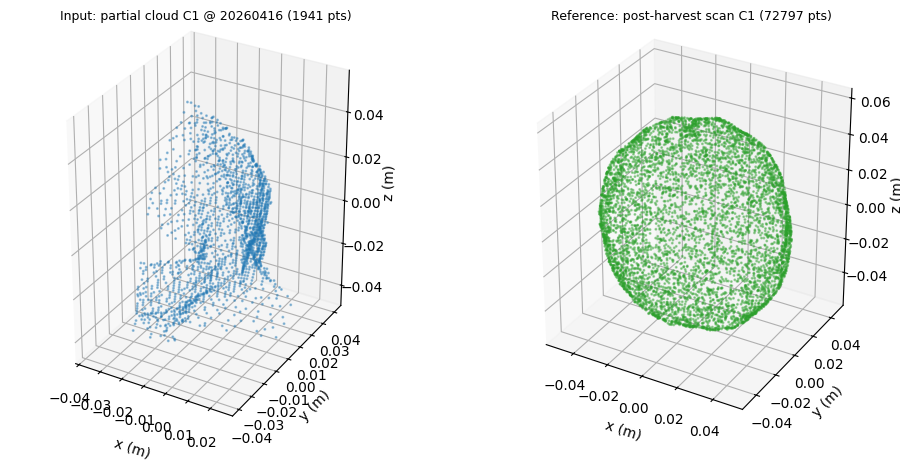

last visit date: 20260416; sequence length for C1: 16 visits


In [ ]:
import matplotlib.pyplot as plt
import numpy as np, open3d as o3d
FRUIT = SELECTED_FRUITS[0]
dates = sorted(p.stem for p in (DATA / "processed" / FRUIT).glob("*.ply"))
LAST = dates[-1]
partial = o3d.io.read_point_cloud(str(DATA / "processed" / FRUIT / f"{LAST}.ply"))
gt = o3d.io.read_point_cloud(str(DATA / "gt" / FRUIT / "pointcloud.ply"))
P = np.asarray(partial.points); G = np.asarray(gt.points)
def sub(a, n=6000):
    return a if len(a) <= n else a[np.random.default_rng(0).choice(len(a), n, replace=False)]
fig = plt.figure(figsize=(10, 4.4))
for i, (pts, title, color) in enumerate([
        (P, f"Input: partial cloud {FRUIT} @ {LAST} ({len(P)} pts)", "tab:blue"),
        (G, f"Reference: post-harvest scan {FRUIT} ({len(G)} pts)", "tab:green")]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    s = sub(pts); ax.scatter(s[:,0], s[:,1], s[:,2], s=1.2, c=color, alpha=0.4)
    ax.set_title(title, fontsize=9); ax.set_box_aspect((np.ptp(s[:,0]), np.ptp(s[:,1]), np.ptp(s[:,2])))
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("z (m)")
plt.tight_layout(); plt.show()
print(f"last visit date: {LAST}; sequence length for {FRUIT}: {len(dates)} visits")

## 7. Fetch the pinned public config and adapt paths to the released v1.0 bundle

The author reference command uses `configs/public/score_public_dataset.json` at the pinned commit. Because the only published weights are **v1.0** (the docs' `v1.1` bundle does not exist), we verify — on the actual downloaded bytes — that the bundle's decoder experiment (`specs.json` → `CodeLength`), the anisotropy basis npz (PC1 direction required by `--fusion_mode ema_max`), and the decoder epoch are consistent, then write an adapted config. Only **paths/flags** are changed; no scientific parameter is edited. Any change is printed. If the bundle is inconsistent with the pinned code, this cell fails loudly rather than silently substituting anything.

日本語: ピン留めされた公開設定 JSON を取得し、実際にダウンロードした v1.0 バンドルの内容(潜在次元・PC1 基底・デコーダ epoch)と照合してパスのみ書き換えます。変更点はすべて表示されます。


In [ ]:
import json, urllib.request, numpy as np, pathlib
CFG_URL = ("https://raw.githubusercontent.com/sungjay-kim/SCoRe/" + PIN +
           "/configs/public/score_public_dataset.json")
cfg = json.loads(urllib.request.urlopen(CFG_URL).read())
print("--- pinned public config ---"); print(json.dumps(cfg, indent=1)[:2200])
# decoder epoch: exactly one expected; else fall back to config value if present
epochs = sorted(int(p.stem) for p in (EXP_DIR / "ModelParameters").glob("*.pth"))
assert epochs, "no decoder checkpoint in bundle"
if len(epochs) == 1:
    EPOCH = epochs[0]
else:
    EPOCH = int(cfg.get("checkpoint_decoder", 0))
    assert EPOCH in epochs, f"ambiguous decoder epochs {epochs} and config value {EPOCH} not among them"
print("decoder epoch:", EPOCH)
# anisotropy basis npz (required by --fusion_mode ema_max for the PC1 direction)
npzs = sorted((REPO / "weights").rglob("*.npz"))
assert len(npzs) == 1, f"expected exactly one anisotropy npz, got {npzs}"
npz = np.load(npzs[0])
print("npz keys:", list(npz.files))
cfg["aniso_npz_path"] = str(npzs[0].relative_to(REPO))
cfg["aniso_K"] = 2 if "v_basis_K2" in npz.files else 1
# path adaptations only
cfg["data_dir"] = str(DATA)
cfg["experiment"] = str(EXP_DIR.relative_to(REPO))
cfg["checkpoint_decoder"] = EPOCH
cfg["save_mesh"] = True  # needed for the 3-D comparison below
cfg["pretrained_encoder"] = str(CKPT_PATH.relative_to(REPO))  # v1.0 bundle checkpoint (doc path pointed at the absent v1.1 name)
if not torch.cuda.is_available() and bool(cfg.get("intermediate_use_softvol", False)):
    cfg["intermediate_use_softvol"] = False
    print("adaptation: intermediate_use_softvol -> False (GPU-only soft volume on a CPU runtime)")
ADAPTED = REPO / "configs" / "public" / "score_public_dataset_v10_adapted.json"
ADAPTED.write_text(json.dumps(cfg, indent=1))
print("changed keys:", {k: cfg[k] for k in ("data_dir", "experiment", "checkpoint_decoder",
                                            "aniso_npz_path", "aniso_K", "save_mesh",
                                            "pretrained_encoder")})
# strict encoder-load pre-flight with the author's own builder; tolerate only
# auxiliary-head (volume/NLL) key mismatches by flipping the corresponding flags.
import sys; sys.path.insert(0, str(REPO))
import _repo_bootstrap  # noqa: F401
from corepp.temporal.core import build_encoder
AUX = ("log_scale", "log_vol", "vol_head", "nll", "super")
for attempt in range(3):
    enc = build_encoder(cfg, LATENT_DIM, torch.device("cpu"))
    missing, unexpected = enc.load_state_dict(ckpt["encoder_state_dict"], strict=False)
    m_bad = [k for k in missing if not any(p in k.lower() for p in AUX)]
    u_bad = [k for k in unexpected if not any(p in k.lower() for p in AUX)]
    if not m_bad and not u_bad:
        break
    if any(("log_vol" in k or "vol_head" in k) for k in unexpected): cfg["volume_head"] = True
    if any(("nll" in k or "log_scale" in k) for k in unexpected): cfg["nll_super_loss"] = True
    if any(("log_vol" in k or "vol_head" in k) for k in missing): cfg["volume_head"] = False
    if any(("nll" in k or "log_scale" in k) for k in missing): cfg["nll_super_loss"] = False
    print(f"adaptation attempt {attempt}: volume_head={cfg.get('volume_head')} nll_super_loss={cfg.get('nll_super_loss')}")
else:
    raise RuntimeError(f"encoder checkpoint/arch mismatch: missing={missing[:5]} unexpected={list(unexpected)[:5]}")
assert not m_bad and not u_bad, f"core encoder mismatch: {m_bad[:5]} / {u_bad[:5]}"
print(f"strict pre-flight OK: all {len(enc_sd)} encoder tensors load at D={LATENT_DIM}"
      + (f" (ignored aux keys: {len(missing)+len(unexpected)})" if (missing or unexpected) else ""))

--- pinned public config ---
{
 "task_name": "score_public_dataset",
 "species": "kmelon",
 "seed": 1337,
 "data_dir": "data/3DKoreanMelon/",
 "split_json": "metadata/splits.json",
 "experiment": "weights/deepsdf_latent32/",
 "checkpoint_decoder": 380,
 "encoder": "point_cloud_maxmean_large_masked",
 "pretrained_encoder": "weights/score_encoder.pt",
 "freeze_encoder": true,
 "use_orbbec_pcd": true,
 "orbbec_pcd_suffix": "",
 "detection_input": "mask",
 "normalize_depth": true,
 "depth_min": 400,
 "depth_max": 900,
 "temporal_arch": "kalman",
 "kalman_init_R": 0.1,
 "growth_mode": "none",
 "min_sequence_length": 3,
 "drop_frame_prob": 0.0,
 "drop_frame_min_keep": 5,
 "delta_time_unit": 86400.0,
 "use_occlusion_augmentation": false,
 "max_occlusion_frac": 0.3,
 "occlusion_apply_prob": 0.4,
 "occlusion_min_points": 64,
 "test_occlusion_levels": "0,10,20,30,40,50,60",
 "loss_final_frame_only": true,
 "lambda_super": 10.0,
 "use_consistency_loss": false,
 "lambda_consistency": 0.0,
 "use_tr

## 8. SCoRe inference (time-aware EMA + PC1 clamp) on the selected sequences

Run the author's `temporal/test.py` exactly as documented (`--fusion_mode ema_max --ema_tau 3.0 --min_n_points 300 --test_occlusion_levels 0`), limited to our 3 sequences with `--max_sequences 3`. Per visit it encodes the partial cloud, fuses the latent with the paper's parameter-free rule, decodes the SDF, extracts a mesh, and computes per-frame volume + final-frame chamfer / F1@5mm against the reference. Output is streamed; the run takes a few minutes.

日本語: 論文の SCoRe 融合(ema_max, τ=3日)で 3 個体の来園シーケンスを推論します。著者スクリプトをそのまま実行します。


In [ ]:
import subprocess, sys, time, shlex
def run_temporal(tag, extra):
    out = REPO / "runs_demo" / tag
    cmd = [sys.executable, "temporal/test.py",
           "--cfg", str(ADAPTED.relative_to(REPO)),
           "--checkpoint", str(CKPT_PATH.relative_to(REPO)),
           "--output_dir", str(out.relative_to(REPO)),
           "--min_n_points", "300", "--test_occlusion_levels", "0",
           "--max_sequences", str(len(SELECTED_FRUITS))] + extra
    print("$", shlex.join(cmd), flush=True); t0 = time.time()
    proc = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    lines = []
    for line in proc.stdout:
        lines.append(line.rstrip())
        print(line, end="", flush=True)
    proc.wait(timeout=120)
    dt = time.time() - t0
    if proc.returncode != 0:
        print(f"\n[{tag}] FAILED exit {proc.returncode} after {dt:.0f} s; last 40 lines:")
        print("\n".join(lines[-40:]))
        raise subprocess.CalledProcessError(proc.returncode, cmd)
    print(f"\n[{tag}] done in {dt:.0f} s")
    return out
OUT_SCORE = run_temporal("score", ["--fusion_mode", "ema_max", "--ema_tau", "3.0"])

$ /usr/bin/python3 temporal/test.py --cfg configs/public/score_public_dataset_v10_adapted.json --checkpoint weights/score_temporal.pt --output_dir runs_demo/score --min_n_points 300 --test_occlusion_levels 0 --max_sequences 3 --fusion_mode ema_max --ema_tau 3.0


I0000 00:00:1793054264.048476    4261 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793054264.125466    4261 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.


To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793054266.833511    4261 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


...

seq: 100%|██████████| 3/3 [00:55<00:00, 18.49s/it]


[temporal-test] Saved metrics to runs_demo/score/eval/shape_completion_results/shape_completion_results.csv


[temporal-test] Saved summary to runs_demo/score/eval/shape_completion_results/shape_completion_metrics_summary.json


[temporal-test] Sweep eval skipped: No module named 'corepp.scripts'



[score] done in 70 s


## 9. Single-frame CoRe++ baseline on the same sequences

The baseline is the *same* fine-tuned encoder with **no fusion** (`--static --static_all_frames`): at every visit only the current partial cloud is encoded and decoded. The difference between the two runs is exactly the temporal latent fusion — the paper's core claim.

日本語: 同一エンコーダで融合なし(--static)の単フレームbaselineを同じシーケンスに実行します。両者の差が時系列融合の効果です。


In [ ]:
OUT_STATIC = run_temporal("static", ["--static", "--static_all_frames"])

$ /usr/bin/python3 temporal/test.py --cfg configs/public/score_public_dataset_v10_adapted.json --checkpoint weights/score_temporal.pt --output_dir runs_demo/static --min_n_points 300 --test_occlusion_levels 0 --max_sequences 3 --static --static_all_frames


I0000 00:00:1793054334.650873    4555 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793054334.731571    4555 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.


To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793054337.418702    4555 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


...

seq: 100%|██████████| 3/3 [00:56<00:00, 18.97s/it]


[temporal-test] Saved metrics to runs_demo/static/eval/shape_completion_results/shape_completion_results.csv


[temporal-test] Saved summary to runs_demo/static/eval/shape_completion_results/shape_completion_metrics_summary.json


[temporal-test] Sweep eval skipped: No module named 'corepp.scripts'



[static] done in 72 s


## 10. Subset results: last-frame volume RMSE / F1@5mm, SCoRe vs. single-frame

Aggregate the author CSVs (`shape_completion_results.csv`) over the **last frame of each selected sequence** (the only frames with reference-scan evaluation): volume RMSE and MAPE against the harvest reference, plus chamfer distance and F1@5mm computed by the author script. These are subset metrics on 3 fruits — reported for transparency, **not** comparable to the paper's 79-fruit table.

日本語: 各個体の最終訪問フレームに限定して体積 RMSE・F1@5mm 等を集計します(3 個体のサブセット値であり、論文の 79 個体の表とは比較しません)。


In [ ]:
import glob, pandas as pd, numpy as np
def load_results(root):
    csvs = sorted(glob.glob(str(root + "/**/shape_completion_results.csv"), recursive=True))
    assert len(csvs) == 1, f"expected one results csv under {root}, got {csvs}"
    df = pd.read_csv(csvs[0])
    last = df[df["frame_idx"] == df["seq_len"] - 1].copy()
    return df, last, csvs[0]
df_s, last_s, csv_s = load_results(str(OUT_SCORE))
df_b, last_b, csv_b = load_results(str(OUT_STATIC))
def summarize(last, name):
    err = last["mesh_volume_ml"] - last["gt_volume_ml"]
    f1_raw = float(last['f1_5mm'].mean())
    f1_pct = f1_raw if f1_raw > 1.5 else f1_raw * 100  # CSV stores percent (verify: raw mean printed below)
    return {"run": name, "fruits": int(last['kmelon_id'].nunique()),
            "vol_RMSE_mL": float(np.sqrt((err**2).mean())),
            "vol_MAPE_%": float((err.abs() / last['gt_volume_ml']).mean() * 100),
            "chamfer_mm": float(last['chamfer_distance'].mean() * 1000),
            "F1@5mm_%": float(f1_pct)}
summary = pd.DataFrame([summarize(last_s, "SCoRe (ema_max, tau=3d)"),
                        summarize(last_b, "Single-frame (static)")])
display(summary)
print("raw f1_5mm column means (as stored by the author script):",
      float(last_s['f1_5mm'].mean()), float(last_b['f1_5mm'].mean()))
summary.to_csv("/content/subset_results_summary.csv", index=False)
print("results csv:", csv_s); print("baseline csv:", csv_b)
print("paper full-test reference (79 fruits): RMSE 50.6 mL, F1@5mm 83.0%, chamfer 2.95 mm (subset values are NOT comparable)")

,run,fruits,vol_RMSE_mL,vol_MAPE_%,chamfer_mm,F1@5mm_%
0,"SCoRe (ema_max, tau=3d)",3,70.066064,8.725788,2.904,81.521400
1,Single-frame (static),3,78.022903,16.749062,3.137,80.474833


raw f1_5mm column means (as stored by the author script): 81.5214 80.47483333333334
results csv: /content/SCoRe/runs_demo/score/eval/shape_completion_results/shape_completion_results.csv
baseline csv: /content/SCoRe/runs_demo/static/eval/shape_completion_results/shape_completion_results.csv
paper full-test reference (79 fruits): RMSE 50.6 mL, F1@5mm 83.0%, chamfer 2.95 mm (subset values are NOT comparable)


## 11. Per-visit volume trajectories

The paper's central object is the **volume trajectory across visits**, not any single frame. We plot, per fruit: the SCoRe mesh volume and the single-frame mesh volume at every visit, the caliper ellipsoid proxy where available (`sfm_volume_ml`), and the harvest reference (dashed line). This graph is generated by this notebook from the runs above; it is not an author figure.

日本語: 各個体の来園ごとの体積推移(SCoRe vs 単フレーム vs カリパー参照、収穫後参照は破線)をプロットします。このノートブックによる追加可視化であり、著者の図ではありません。


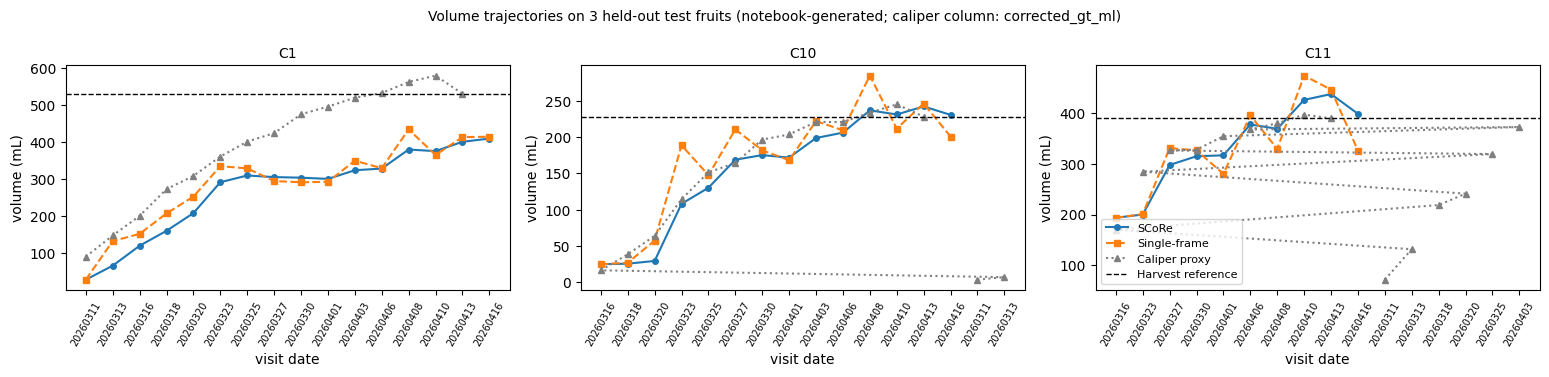

In [ ]:
import matplotlib.pyplot as plt
CALIPER_COL = "corrected_gt_ml" if "corrected_gt_ml" in sess.columns else "ellipsoid_ml"
fig, axes = plt.subplots(1, len(SELECTED_FRUITS), figsize=(5.2 * len(SELECTED_FRUITS), 3.8), squeeze=False)
for ax, fruit in zip(axes[0], SELECTED_FRUITS):
    for df, label, style in ((df_s, "SCoRe", "o-"), (df_b, "Single-frame", "s--")):
        d = df[df["kmelon_id"] == fruit].sort_values("frame_idx")
        ax.plot(d["frame_id"].astype(str), d["mesh_volume_ml"], style, label=label, ms=4)
    cal = sess[(sess[IDCOL] == fruit) & (sess["has_caliper"] == True)][["session_date", CALIPER_COL]]
    cal = cal.sort_values("session_date")
    ax.plot(cal["session_date"].astype(str), cal[CALIPER_COL], "^:", label="Caliper proxy", ms=5, color="tab:gray")
    gt = df_s[df_s["kmelon_id"] == fruit]["gt_volume_ml"].iloc[0]
    ax.axhline(gt, ls="--", c="k", lw=1, label="Harvest reference")
    ax.set_title(f"{fruit}", fontsize=10); ax.set_xlabel("visit date"); ax.set_ylabel("volume (mL)")
    ax.tick_params(axis="x", rotation=60, labelsize=7)
axes[0][-1].legend(fontsize=8)
plt.suptitle(f"Volume trajectories on 3 held-out test fruits (notebook-generated; caliper column: {CALIPER_COL})", fontsize=10)
plt.tight_layout(); plt.show()

## 12. Final-frame shape comparison: input vs. SCoRe vs. single-frame vs. reference

For the first selected fruit we render the last visit's **partial input**, the **SCoRe completion**, the **single-frame completion** (meshes saved by the author script), and the **post-harvest reference scan** as point clouds. Reference geometry and model predictions are labeled distinctly.

日本語: 最終訪問の部分入力・SCoRe 完成形状・単フレーム完成形状・収穫後参照スキャンを並べて表示します(参照と予測は別の色で明示)。


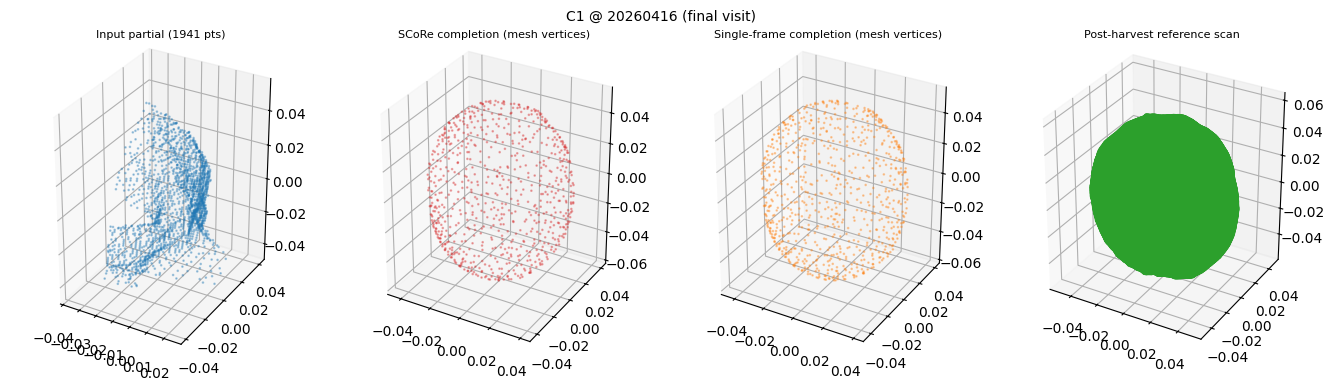

In [ ]:
import glob, open3d as o3d, numpy as np, matplotlib.pyplot as plt
mesh_files = sorted(glob.glob(str(OUT_SCORE) + "/**/meshes/*.ply", recursive=True))
f_last = [m for m in mesh_files if m.endswith(f"{FRUIT}_{LAST}_mesh.ply")]
b_last = [m for m in glob.glob(str(OUT_STATIC) + "/**/meshes/*.ply", recursive=True) if m.endswith(f"{FRUIT}_{LAST}_mesh.ply")]
assert f_last and b_last, f"meshes not found: {f_last} {b_last}"
def verts_of(path, n=6000):
    m = o3d.io.read_triangle_mesh(path)
    v = np.asarray(m.vertices)
    return v if len(v) <= n else v[np.random.default_rng(0).choice(len(v), n, replace=False)]
panels = [(P, f"Input partial ({len(P)} pts)", "tab:blue"),
          (verts_of(f_last[0]), "SCoRe completion (mesh vertices)", "tab:red"),
          (verts_of(b_last[0]), "Single-frame completion (mesh vertices)", "tab:orange"),
          (G, "Post-harvest reference scan", "tab:green")]
fig = plt.figure(figsize=(13.5, 3.6))
for i, (pts, title, color) in enumerate(panels):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.scatter(pts[:,0], pts[:,1], pts[:,2], s=0.8, c=color, alpha=0.35)
    ax.set_title(title, fontsize=8); ax.set_box_aspect((np.ptp(pts[:,0]), np.ptp(pts[:,1]), np.ptp(pts[:,2])))
plt.suptitle(f"{FRUIT} @ {LAST} (final visit)", fontsize=10)
plt.tight_layout(); plt.show()

## Interpretation, limitations, references

**What was executed:** released SCoRe inference (commit-pinned author code, v1.0 weights) on 3 held-out test fruits; single-frame vs. temporal-fusion comparison; per-visit volume trajectories; last-frame subset metrics; input/reference visualization. The notebook runs on CPU or T4 (auto-detected above).

**Limitations:** (1) subset metrics on 3 fruits are not the paper's 79-fruit benchmark; (2) only weights release `v1.0` exists — the repository docs reference `v1.1`, which was never published, so the doc-stated public-path metrics (2.97 mm / 82.7 % / 52.3 mL) correspond to the unavailable bundle and the v1.0 release notes state their own reference values (2.76 mm / 86.6 % / 47.2 mL); our subset values may differ from both for the additional reason that they cover only 3 fruits; (3) the harvest reference in the release is the convex hull of the released scan (authors document a ~0.7 % bias vs. the paper's screened-Poisson meshes); (4) intermediate-visit volumes are compared against a caliper ellipsoid *proxy*, not a scan; (5) the paper's full text (SSRN) was not accessible — methods understanding here rests on the authors' released code, docs, and the Crossref-deposited abstract.

**References:** SCoRe repository `sungjay-kim/SCoRe` @ `b8fc9c652f30865e808be012aa3a89c0f5c42aaf`; dataset `Sungjay/3DKoreanMelon` (DOI 10.57967/hf/9982, CC BY 4.0); weights release v1.0; builds on CoRe++ (Blok et al. 2025) and DeepSDF (Park et al. 2019).

日本語: 上記の通り、本ノートブックは公開済み重みによる推論デモ(テスト 3 個体)です。論文の 79 個体ベンチマーク値とは比較できません。v1.1 重みは未公開のため v1.0 を使用しました。体積参照は凸包ベースであり、論文の Poisson メッシュ参照とは約 0.7% の系統差が著者により文書化されています。

*Notebook prepared by an AI-assisted reproduction pipeline (PhenoPaper); author code unmodified except documented path/flag adaptations printed in cells 7–9.*
